# Chapitre 13 - Les k plus proches voisins (cours 2)

Ce second notebook traite des **k plus proches voisins** (k-ppv) :

1. la règle des k-ppv et le choix de $k$ (figures 13.3 et 13.4 du livre) ;
2. le résultat de Cover et Hart : asymptotiquement, le 1-ppv fait au plus deux fois
   l'erreur de Bayes ;
3. les **métriques invariantes** et la **distance tangente**, illustrées sur les chiffres
   manuscrits (figures 13.9-13.11, tableau 13.1) ;
4. le fléau de la dimension et les **métriques adaptatives** (DANN, figures 13.12-13.15),
   ainsi que la réduction de dimension globale ;
5. le **coût calculatoire** et les méthodes de condensation (section 13.5).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch13_prototypes as cp
from matplotlib.colors import ListedColormap
set_style()
PURPLE = COLORS[6]

## 1. La règle des k plus proches voisins

Les k-ppv sont une méthode **à mémoire** : aucun modèle n'est ajusté, on conserve
tout l'échantillon d'apprentissage. Pour classer un point $x_0$ :

1. on calcule les distances $d_{i} = \|x_i - x_0\|$ (éq. (13.1) du livre), après
   avoir standardisé les variables ;
2. on retient les $k$ points $x_{(1)}, \dots, x_{(k)}$ les plus proches ;
3. on prédit la classe **majoritaire** parmi leurs étiquettes (égalités tranchées au
   hasard).

Avec $k = 1$, chaque point d'apprentissage est son propre prototype : c'est le cas
extrême des méthodes du notebook précédent.

> **Intuition (biais et variance).** Le vote des $k$ voisins estime localement les
> probabilités $p_j(x_0) = \Pr(G = j \mid X = x_0)$ par des fréquences.
> * $k$ petit : on n'utilise que des points très proches de $x_0$ (faible **biais**),
>   mais la fréquence repose sur peu d'observations (forte **variance**) ;
> * $k$ grand : la moyenne est plus stable, mais elle mélange des points éloignés où
>   les probabilités sont différentes (biais).
>
> Le nombre « effectif » de paramètres est de l'ordre de $N/k$ (autant que de
> voisinages disjoints).

## 2. Figure 13.3 : la simulation à trois classes

Nous reprenons la simulation à trois classes du notebook précédent (même graine), et
la même fonction de tracé des régions.

In [2]:
rng = np.random.RandomState(2)
base = np.array([[-1.5, 1.0], [1.5, 1.0], [0.0, -1.5]])
means3 = [b + 0.8 * rng.randn(10, 2) for b in base]
sigma2_3 = 0.2
X3, y3 = cp.sample_gaussian_mixture(means3, 100, sigma2_3, rng)
X3_test, y3_test = cp.sample_gaussian_mixture(means3, 3000, sigma2_3, rng)
bayes3_rule = lambda G: cp.mixture_posterior(G, means3, sigma2_3).argmax(1)
print("Erreur de Bayes : %.3f" % np.mean(bayes3_rule(X3_test) != y3_test))


def plot_regions(ax, predict, X, y, bayes=None, xlim=(-4, 4), ylim=(-4, 4), n=250, ncls=3):
    xx, yy, grid = decision_grid(xlim, ylim, n)
    cmap = ListedColormap(COLORS[:ncls])
    Z = predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(ncls + 1) - 0.5, cmap=cmap, alpha=0.15)
    ax.contour(xx, yy, Z, levels=np.arange(ncls) + 0.5, colors="k", linewidths=1)
    if bayes is not None:
        ax.contour(xx, yy, bayes(grid).reshape(xx.shape), levels=np.arange(ncls) + 0.5,
                   colors=PURPLE, linewidths=1.5, linestyles="--")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, s=12, alpha=0.8, vmin=0, vmax=ncls - 1)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$X_1$", ylabel="$X_2$")

Erreur de Bayes : 0.073


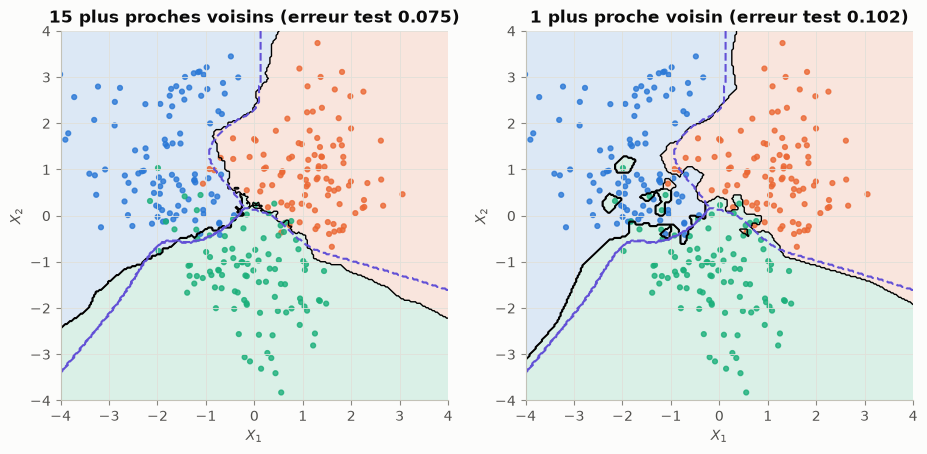

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, k in zip(axes, (15, 1)):
    err = np.mean(cp.knn_predict(X3, y3, X3_test, k) != y3_test)
    plot_regions(ax, lambda G, k=k: cp.knn_predict(X3, y3, G, k), X3, y3, bayes3_rule)
    ax.set_title("%d plus proche%s voisin%s (erreur test %.3f)"
                 % (k, "s" if k > 1 else "", "s" if k > 1 else "", err))
plt.show()

Avec 15 voisins, la frontière est assez régulière et suit bien celle de Bayes ; avec
un seul voisin elle est très découpée : des îlots entourent les points isolés. Le
1-ppv a une erreur d'apprentissage nulle (chaque point est son propre voisin), ce qui
ne dit rien de son erreur test.

## 3. Figure 13.4 : choix de k sur les données « mixture »

Sur la simulation à deux classes du chapitre 2, nous traçons en fonction de $k$ :

* l'erreur d'**apprentissage** ;
* l'erreur **test** (10 000 points simulés selon le vrai modèle) ;
* l'erreur de **validation croisée à 10 blocs**, avec une barre d'erreur standard :
  l'erreur VC est la moyenne de 10 erreurs de blocs $e_1, \dots, e_{10}$, on l'accompagne
  de $\widehat{\mathrm{se}} = s/\sqrt{10}$ où $s$ est l'écart-type empirique des $e_b$.

In [4]:
mix = datasets.load_mixture_example()
Xm, ym = mix["x"], mix["y"]
means_m = [mix["means"][:10], mix["means"][10:]]
Xm_test, ym_test = cp.sample_gaussian_mixture(means_m, 5000, 0.2, np.random.RandomState(0))
bayes_m_rule = lambda G: cp.mixture_posterior(G, means_m, 0.2).argmax(1)
bayes_m = np.mean(bayes_m_rule(Xm_test) != ym_test)

ks = np.arange(1, 31)
err_train = (cp.knn_from_dists(cp.sq_dists(Xm, Xm), ym, ks) != ym).mean(1)
err_test = (cp.knn_from_dists(cp.sq_dists(Xm_test, Xm), ym, ks) != ym_test).mean(1)
cv_mean, cv_se = cp.knn_cv_error(Xm, ym, ks, n_folds=10, rng=np.random.RandomState(1))

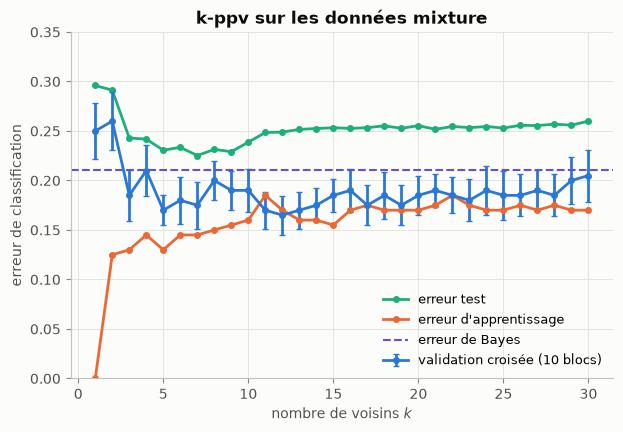

In [5]:
fig, ax = plt.subplots()
ax.plot(ks, err_test, "o-", color=COLORS[2], ms=4, label="erreur test")
ax.errorbar(ks, cv_mean, yerr=cv_se, fmt="o-", color=BLUE, ms=4, capsize=2,
            label="validation croisée (10 blocs)")
ax.plot(ks, err_train, "o-", color=ORANGE, ms=4, label="erreur d'apprentissage")
ax.axhline(bayes_m, color=PURPLE, ls="--", lw=1.5, label="erreur de Bayes")
ax.set(title="k-ppv sur les données mixture", xlabel="nombre de voisins $k$",
       ylabel="erreur de classification", ylim=(0, 0.35))
ax.legend()
plt.show()

In [6]:
k_best_test = ks[err_test.argmin()]
k_best_cv = ks[cv_mean.argmin()]
print("k minimisant l'erreur test : %d (erreur %.3f)" % (k_best_test, err_test.min()))
print("k minimisant l'erreur VC   : %d (erreur VC %.3f)" % (k_best_cv, cv_mean.min()))

k minimisant l'erreur test : 7 (erreur 0.225)
k minimisant l'erreur VC   : 12 (erreur VC 0.165)


Le livre retient $k = 7$, qui minimise (à peu près) l'erreur test. L'erreur VC est
assez plate autour de son minimum, et ses barres d'erreur standard sont larges : de
nombreuses valeurs de $k$ sont statistiquement indiscernables.

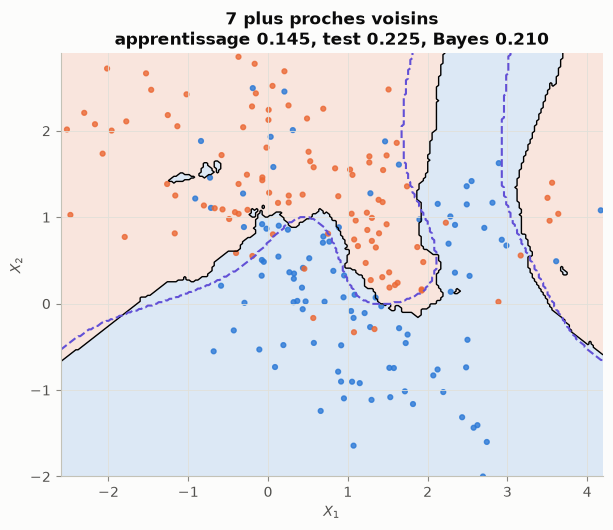

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))
pred7 = lambda G: cp.knn_predict(Xm, ym, G, 7)
plot_regions(ax, pred7, Xm, ym, bayes_m_rule, (-2.6, 4.2), (-2.0, 2.9), ncls=2)
ax.set_title("7 plus proches voisins\napprentissage %.3f, test %.3f, Bayes %.3f"
             % (np.mean(pred7(Xm) != ym), np.mean(pred7(Xm_test) != ym_test), bayes_m))
plt.show()

## 4. Le théorème de Cover et Hart

### 4.1 L'idée

Supposons qu'il y ait énormément de données d'apprentissage, en dimension fixée :
le plus proche voisin $x_{(1)}$ de $x$ est alors pratiquement **confondu** avec $x$
(le biais disparaît). Notons $p_k(x)$ les vraies probabilités des classes en $x$, et
$k^* = \arg\max_k p_k(x)$ la classe dominante.

* La règle de Bayes prédit $k^*$ ; elle se trompe avec probabilité (éq. (13.2))
  $$1 - p_{k^*}(x).$$
* Le 1-ppv prédit l'étiquette $G'$ du voisin, qui est (asymptotiquement) **une
  variable indépendante** de l'étiquette $G$ du point test, de même loi
  $(p_1(x), \dots, p_K(x))$. Il se trompe quand $G' \ne G$, d'où l'erreur (éq. (13.3))
  $$\Pr(G' \ne G) = \sum_{k=1}^K \Pr(G' = k)\Pr(G \ne k) = \sum_{k=1}^K p_k(x)\big(1 - p_k(x)\big).$$

Pour $K = 2$, en notant $p = p_{k^*}(x) \ge 1/2$, l'erreur du 1-ppv vaut
$2p(1-p) \le 2(1-p)$ : **au plus deux fois l'erreur de Bayes**. Plus généralement
(éq. (13.5), démontrée dans l'exercice 13.3) :

$$\sum_{k=1}^K p_k(x)(1 - p_k(x)) \le 2\big(1 - p_{k^*}(x)\big) - \frac{K}{K-1}\big(1 - p_{k^*}(x)\big)^2 .$$

En intégrant en $x$, l'erreur asymptotique $E_1$ du 1-ppv vérifie
$E^* \le E_1 \le E^*\big(2 - \frac{K}{K-1}E^*\big)$ où $E^*$ est l'erreur de Bayes.

> **Remarque.** Ce résultat donne une idée de la meilleure performance possible :
> si le 1-ppv fait 10 % d'erreur, l'erreur de Bayes est (asymptotiquement) au moins
> d'environ 5 %. Mais tout repose sur l'hypothèse « biais nul », qui peut être très
> fausse en pratique, surtout en grande dimension.

### 4.2 Vérification numérique

Prenons $X$ uniforme sur $[0, 1]$ et deux classes avec $p_2(x) = x$. Alors
$E^* = \mathbb E[\min(X, 1-X)] = 1/4$, la limite du 1-ppv est
$E_1 = \mathbb E[2X(1-X)] = 2(\tfrac12 - \tfrac13) = 1/3$, et la borne vaut
$2E^*(1-E^*) = 3/8$.

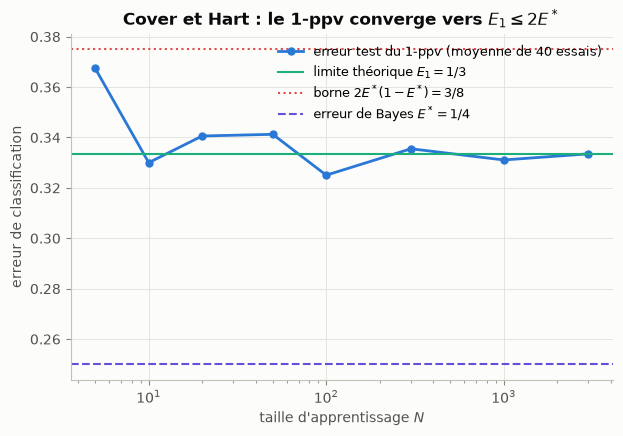

In [8]:
rng = np.random.RandomState(0)
Ns = [5, 10, 20, 50, 100, 300, 1000, 3000]
err1 = []
for N in Ns:
    e = []
    for rep in range(40):
        x = rng.uniform(size=N)
        g = (rng.uniform(size=N) < x).astype(int)
        xt = rng.uniform(size=2000)
        gt = (rng.uniform(size=2000) < xt).astype(int)
        nn = np.abs(xt[:, None] - x[None, :]).argmin(1)
        e.append(np.mean(g[nn] != gt))
    err1.append(np.mean(e))

fig, ax = plt.subplots()
ax.semilogx(Ns, err1, "o-", color=BLUE, label="erreur test du 1-ppv (moyenne de 40 essais)")
ax.axhline(1 / 3, color=COLORS[2], ls="-", lw=1.5, label="limite théorique $E_1 = 1/3$")
ax.axhline(3 / 8, color=COLORS[7], ls=":", lw=1.5, label="borne $2E^*(1-E^*) = 3/8$")
ax.axhline(1 / 4, color=PURPLE, ls="--", lw=1.5, label="erreur de Bayes $E^* = 1/4$")
ax.set(title="Cover et Hart : le 1-ppv converge vers $E_1 \\leq 2E^*$",
       xlabel="taille d'apprentissage $N$", ylabel="erreur de classification")
ax.legend()
plt.show()

## 5. Métriques invariantes et distance tangente

### 5.1 Les chiffres manuscrits

Les données **zip** (service postal américain) contiennent des images $16 \times 16$
en niveaux de gris de chiffres manuscrits : chaque image est un vecteur de
$\mathbb{R}^{256}$. 7291 images d'apprentissage, 2007 images test.

(7291, 256) (2007, 256)


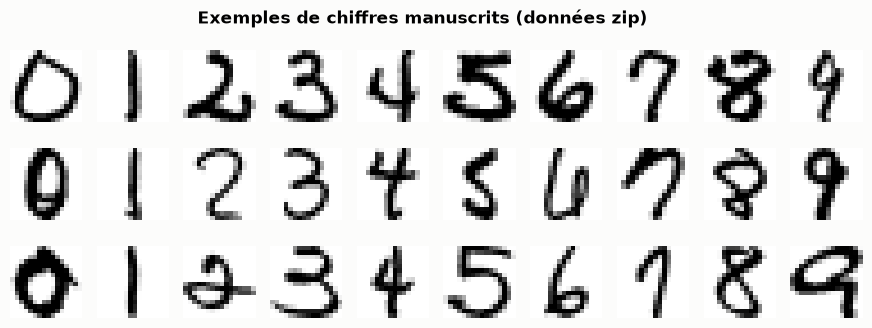

In [9]:
Xz, yz = datasets.load_zip("train")
Xz_test, yz_test = datasets.load_zip("test")
print(Xz.shape, Xz_test.shape)

fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
for d in range(10):
    idx = np.where(yz == d)[0][:3]
    for r in range(3):
        axes[r, d].imshow(Xz[idx[r]].reshape(16, 16), cmap="gray_r")
        axes[r, d].axis("off")
fig.suptitle("Exemples de chiffres manuscrits (données zip)", fontweight="bold")
plt.show()

### 5.2 Invariance par rotation

Un « 3 » légèrement tourné reste un « 3 ». Pourtant, en tant que vecteur de
$\mathbb{R}^{256}$, il peut être **loin** de l'original en distance euclidienne. L'ensemble
des versions tournées d'une image décrit une **courbe** de $\mathbb R^{256}$
(une variété d'invariance, de dimension 1).

Pour fabriquer des images transformées, nous prolongeons l'image discrète en une fonction
lisse $\hat F : \mathbb R^2 \to \mathbb R$ par un **lisseur à noyau gaussien**
(chapitre 6) :

$$\hat F(u) = \frac{\sum_j K_h(u - u_j)\,F_j}{\sum_j K_h(u - u_j)}, \qquad K_h(t) = e^{-\|t\|^2/(2h^2)},$$

où $u_j$ est le centre du pixel $j$ et $F_j$ son niveau de gris. L'image tournée
d'un angle $\alpha$ s'obtient en évaluant $\hat F$ aux points $R_\alpha u_j$.

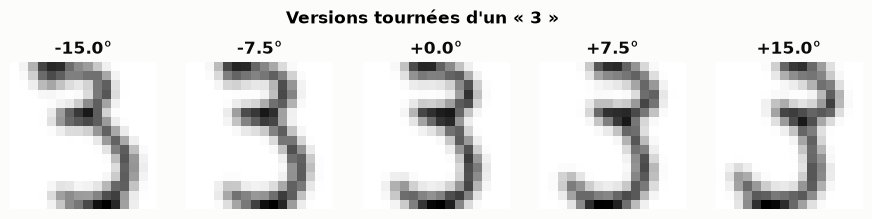

In [10]:
x3 = Xz[np.where(yz == 3)[0][4]]
angles = [-15, -7.5, 0, 7.5, 15]
fig, axes = plt.subplots(1, 5, figsize=(11, 2.6))
for ax, a in zip(axes, angles):
    ax.imshow(cp.transform_image(x3, cp.rotation_matrix(np.deg2rad(a))).reshape(16, 16), cmap="gray_r")
    ax.set_title("%+.1f°" % a)
    ax.axis("off")
fig.suptitle("Versions tournées d'un « 3 »", fontweight="bold")
plt.show()

### 5.3 La tangente

L'idée de Simard et al. (1993) : remplacer la courbe $\alpha \mapsto x(\alpha)$ des
images tournées par sa **tangente** en $\alpha = 0$,

$$x(\alpha) \approx x + \alpha\, t, \qquad t = \frac{d x(\alpha)}{d\alpha}\Big|_{\alpha=0}.$$

Par la règle de dérivation des fonctions composées (exercice 13.4), en notant
$u = (u_1, u_2)$ les coordonnées du pixel et $\hat F_{u_1}, \hat F_{u_2}$ les dérivées
partielles de l'image lissée,

$$t(u) = \frac{d}{d\alpha} \hat F(R_\alpha u)\Big|_{\alpha=0} = -u_2\,\hat F_{u_1}(u) + u_1\,\hat F_{u_2}(u),$$

car $\frac{d}{d\alpha} R_\alpha u \big|_{\alpha = 0} = (-u_2, u_1)$. Le vecteur tangent
se calcule donc à partir des deux **dérivées spatiales** de l'image.

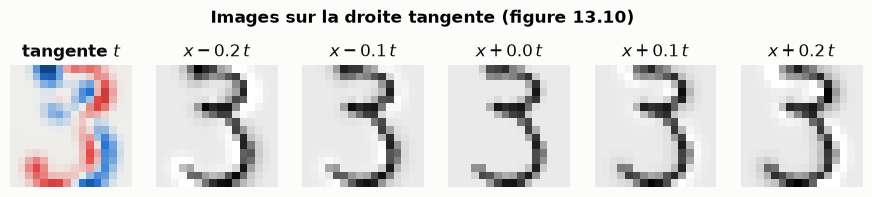

In [11]:
t_rot = cp.image_tangents(x3, which=("rotation",))[0, 0]
fig, axes = plt.subplots(1, 6, figsize=(11, 2.4))
axes[0].imshow(t_rot.reshape(16, 16), cmap=DIV, vmin=-np.abs(t_rot).max(), vmax=np.abs(t_rot).max())
axes[0].set_title("tangente $t$")
for ax, a in zip(axes[1:], [-0.2, -0.1, 0, 0.1, 0.2]):
    ax.imshow((x3 + a * t_rot).reshape(16, 16), cmap="gray_r", vmin=-1.2, vmax=1.2)
    ax.set_title("$x %+.1f\\,t$" % a)
for ax in axes:
    ax.axis("off")
fig.suptitle("Images sur la droite tangente (figure 13.10)", fontweight="bold")
plt.show()

Pour de petits $\alpha$, $x + \alpha t$ ressemble bien à un « 3 » tourné ; pour de
grands $\alpha$, l'image devient méconnaissable. C'est voulu : la tangente ne
capture que les **petites** transformations (on évite ainsi qu'un « 6 » tourné de
180° ressemble à un « 9 »).

### 5.4 La distance tangente

Le livre considère en fait 7 transformations : 2 translations, rotation,
2 homothéties (selon chaque axe), cisaillement et épaisseur du trait. Chaque image $x$
reçoit un **plan tangent** $\{x + T_x a : a \in \mathbb R^7\}$, où les colonnes de
$T_x$ ($256 \times 7$) sont les vecteurs tangents. La **distance tangente** entre deux
images est la plus courte distance entre leurs plans tangents :

$$d_T(x, z)^2 = \min_{a, b \in \mathbb{R}^7} \big\| x + T_x a - z - T_z b \big\|^2 .$$

C'est un problème de **moindres carrés** à 14 inconnues : en posant
$A = [T_x, -T_z]$ et $c = (a, b)$, on minimise $\|A c - (z - x)\|^2$, dont la solution
vérifie les équations normales $A^TA\,c = A^T(z - x)$.

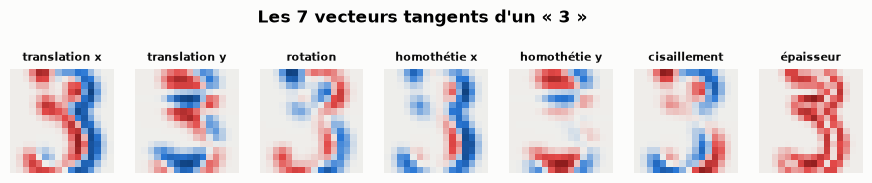

In [12]:
T3 = cp.image_tangents(x3)[0]
fig, axes = plt.subplots(1, 7, figsize=(11, 2.3))
for ax, t, name in zip(axes, T3, cp.TANGENT_NAMES):
    m = np.abs(t).max()
    ax.imshow(t.reshape(16, 16), cmap=DIV, vmin=-m, vmax=m)
    ax.set_title(name, fontsize=8)
    ax.axis("off")
fig.suptitle("Les 7 vecteurs tangents d'un « 3 »", fontweight="bold")
plt.show()

### 5.5 Tableau 13.1 : 1-ppv euclidien contre distance tangente

Calculer la distance tangente entre chaque image test et les 7291 images
d'apprentissage serait coûteux. Nous utilisons une astuce classique : on
présélectionne les 50 plus proches voisins **euclidiens**, et l'on calcule la distance
tangente seulement pour eux. Comme dans Simard et al., les images sont d'abord
légèrement lissées (même noyau, $h = 0{,}7$).

In [13]:
t0 = time.time()
err_eucl = np.mean(yz[cp.sq_dists(Xz_test, Xz).argmin(1)] != yz_test)
print("1-ppv euclidien : erreur test %.3f  (%.1f s)" % (err_eucl, time.time() - t0))

t0 = time.time()
S, _, _ = cp.smoother_matrices(16, h=0.7)
Xs, Xs_test = Xz @ S.T, Xz_test @ S.T
T_train = cp.image_tangents(Xz, h=0.7)
T_test = cp.image_tangents(Xz_test, h=0.7)
pred_td = cp.tangent_nn_predict(Xs, yz, Xs_test, T_train, T_test, n_candidates=50)
err_td = np.mean(pred_td != yz_test)
print("1-ppv tangent   : erreur test %.3f  (%.1f s)" % (err_td, time.time() - t0))

1-ppv euclidien : erreur test 0.056  (0.1 s)


1-ppv tangent   : erreur test 0.029  (2.2 s)


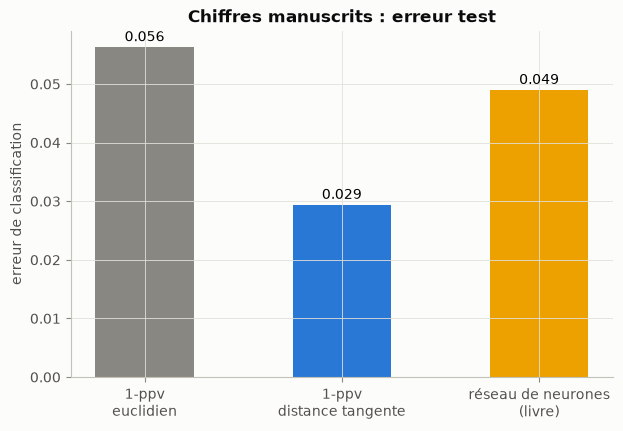

In [14]:
fig, ax = plt.subplots()
labels = ["1-ppv\neuclidien", "1-ppv\ndistance tangente"]
ax.bar(labels, [err_eucl, err_td], color=[GRAY, BLUE], width=0.5)
ax.bar(["réseau de neurones\n(livre)"], [0.049], color=COLORS[3], width=0.5)
for i, v in enumerate([err_eucl, err_td, 0.049]):
    ax.text(i, v + 0.001, "%.3f" % v, ha="center", color="k")
ax.set(title="Chiffres manuscrits : erreur test", ylabel="erreur de classification")
plt.show()

Nous retrouvons l'ordre de grandeur du tableau 13.1 du livre (0,055 pour le 1-ppv
euclidien, 0,026 pour la distance tangente) : l'invariance aux petites
transformations **divise l'erreur par près de deux**.

> **Remarque (« hints »).** Une alternative plus simple consiste à ajouter à
> l'échantillon d'apprentissage des copies transformées de chaque image. Cela marche
> quand l'espace des transformations est petit (voir l'exercice 13.8), mais devient
> impraticable avec 7 transformations simultanées.

## 6. Le fléau de la dimension et les métriques adaptatives

### 6.1 Les voisins sont loin

Pour $N$ points uniformes dans le cube $[-\tfrac12, \tfrac12]^p$, le rayon $R$ du
1-voisinage de l'origine a pour médiane (éq. (13.7), démontrée dans l'exercice 13.2)

$$\operatorname{med}(R) = v_p^{-1/p}\Big(1 - \tfrac{1}{2^{1/N}}\Big)^{1/p},$$

où $v_p r^p$ est le volume de la boule de rayon $r$ en dimension $p$.

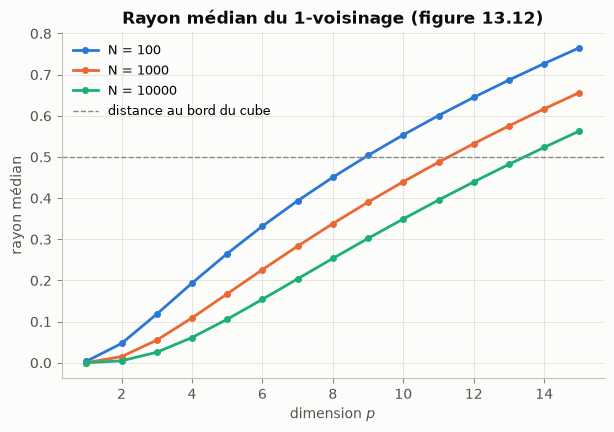

In [15]:
ps = np.arange(1, 16)
fig, ax = plt.subplots()
for N, col in zip([100, 1000, 10000], COLORS):
    ax.plot(ps, [cp.median_nn_radius(N, p) for p in ps], "o-", color=col, ms=4, label="N = %d" % N)
ax.axhline(0.5, color=GRAY, ls="--", lw=1, label="distance au bord du cube")
ax.set(title="Rayon médian du 1-voisinage (figure 13.12)", xlabel="dimension $p$",
       ylabel="rayon médian")
ax.legend()
plt.show()

Dès $p \approx 10$, le plus proche voisin est en médiane presque aussi loin que le
bord du cube, même avec 10 000 points : le « voisinage » n'est plus local, d'où un
**biais** important.

### 6.2 Étirer le voisinage là où rien ne change

Le k-ppv suppose implicitement que les probabilités de classe sont **à peu près
constantes** dans le voisinage. Si elles ne varient que dans certaines directions, on
a intérêt à **étirer** le voisinage dans les autres directions : on réduit le biais
sans augmenter la variance (le voisinage contient toujours $k$ points).

Illustration (figure 13.13) : deux classes séparées par la droite verticale $X_1 = 0{,}55$.

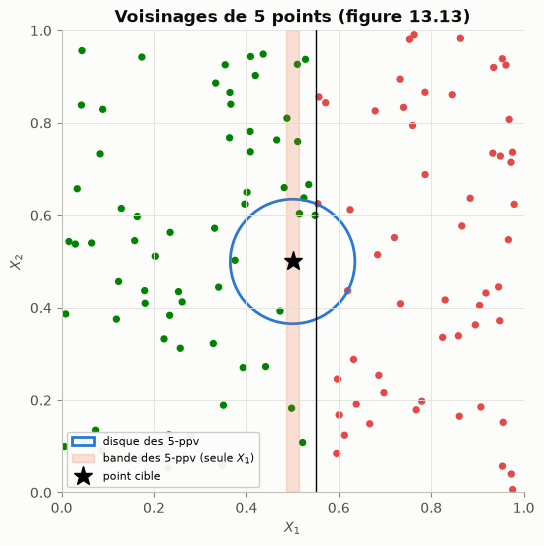

classes des 5-ppv (disque) : [0 0 0 0 1]  (bande) : [0 0 0 0 0]


In [16]:
rng = np.random.RandomState(4)
U = rng.uniform(size=(120, 2))
yU = (U[:, 0] > 0.55).astype(int)
x0 = np.array([0.5, 0.5])
d_circ = np.sqrt(((U - x0) ** 2).sum(1))
d_strip = np.abs(U[:, 0] - x0[0])
nn_c, nn_s = np.argsort(d_circ)[:5], np.argsort(d_strip)[:5]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(U[:, 0], U[:, 1], c=yU, cmap=ListedColormap([COLORS[5], COLORS[7]]), s=18)
ax.axvline(0.55, color="k", lw=1)
r = d_circ[nn_c].max()
ax.add_patch(plt.Circle(x0, r, fill=False, color=BLUE, lw=2, label="disque des 5-ppv"))
w = d_strip[nn_s].max()
ax.axvspan(x0[0] - w, x0[0] + w, color=ORANGE, alpha=0.2, label="bande des 5-ppv (seule $X_1$)")
ax.plot(*x0, "k*", ms=14, label="point cible")
ax.set(title="Voisinages de 5 points (figure 13.13)", xlabel="$X_1$", ylabel="$X_2$",
       xlim=(0, 1), ylim=(0, 1), aspect="equal")
ax.legend(loc="lower left", fontsize=8, frameon=True, framealpha=0.95)
plt.show()

print("classes des 5-ppv (disque) :", yU[nn_c], " (bande) :", yU[nn_s])

### 6.3 La métrique DANN

La méthode **DANN** (*discriminant adaptive nearest-neighbor*, Hastie et Tibshirani)
adapte la métrique en chaque point test $x_0$ :

1. on forme un voisinage de $x_0$ (par exemple 50 points) ;
2. on y calcule la matrice de covariance **intra-classe** poolée
   $W = \sum_k \pi_k W_k$ et la matrice **inter-classes**
   $B = \sum_k \pi_k (\bar x_k - \bar x)(\bar x_k - \bar x)^T$ ;
3. on utilise la distance (éq. (13.8) et (13.9) du livre)
   $$D(x, x_0) = (x - x_0)^T \Sigma\, (x - x_0), \qquad
   \Sigma = W^{-1/2}\big[W^{-1/2} B W^{-1/2} + \epsilon I\big] W^{-1/2}.$$

**Lecture de la formule.** Posons $z = W^{-1/2}x$ : c'est un changement de variables
qui « sphérise » les données (la covariance intra-classe devient l'identité).
Dans ces coordonnées, $D = (z - z_0)^T [B^* + \epsilon I](z - z_0)$ où
$B^* = W^{-1/2}BW^{-1/2}$ est la matrice inter-classes des données sphérisées.

* Dans une direction propre de $B^*$ de valeur propre **nulle**, les moyennes de
  classes ne diffèrent pas : la distance n'y est pénalisée que par $\epsilon$, le
  voisinage s'y **étire**.
* Dans une direction de forte valeur propre, les classes se séparent : la distance y
  est fortement pénalisée, le voisinage s'y **resserre**.
* $\epsilon$ (le livre conseille $\epsilon = 1$) arrondit le voisinage : sans lui, ce
  serait une bande infinie.

Dans une zone où une seule classe est présente, $B = 0$ et $\Sigma = \epsilon W^{-1}$ :
le voisinage reste « rond » (après sphérisation).

### 6.4 Figure 13.14 : deux classes concentriques

Une classe entoure l'autre. Aux points de la frontière, les voisinages DANN
(15 voisins, métrique estimée sur 50 voisins) s'étirent **parallèlement à la
frontière**, c'est-à-dire orthogonalement à la direction où la classe change.

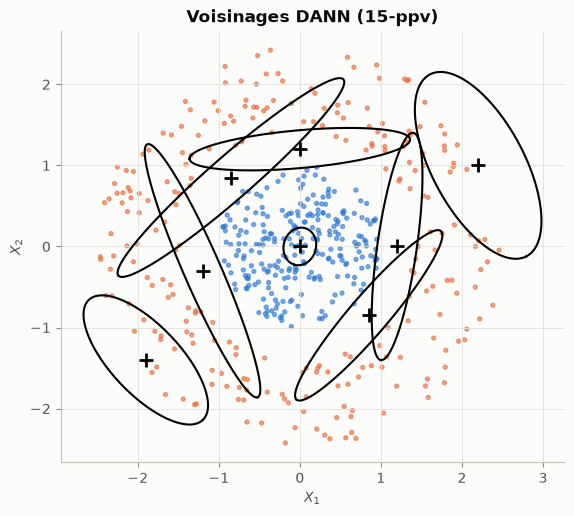

In [17]:
rng = np.random.RandomState(0)
n = 250
Zc = rng.randn(4 * n, 2)
r2 = (Zc ** 2).sum(1)
inner = Zc[r2 < 1.0][:n]
outer_ang = rng.uniform(0, 2 * np.pi, n)
outer_rad = rng.uniform(1.4, 2.5, n)
outer = np.column_stack([outer_rad * np.cos(outer_ang), outer_rad * np.sin(outer_ang)])
Xc = np.vstack([inner, outer])
yc = np.repeat([0, 1], [len(inner), n])

queries = np.array([[1.2, 0], [0, 1.2], [-0.85, 0.85], [0.85, -0.85], [-1.2, -0.3],
                    [0, 0], [2.2, 1.0], [-1.9, -1.4]])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap=TWO_CLASS, s=8, alpha=0.6)
th = np.linspace(0, 2 * np.pi, 200)
for q in queries:
    nb = np.argsort(((Xc - q) ** 2).sum(1))[:50]
    Sig = cp.dann_metric(Xc[nb], yc[nb], eps=1.0)
    d = np.einsum("ij,jk,ik->i", Xc - q, Sig, Xc - q)
    rad = np.sort(d)[14]                       # rayon du 15-voisinage
    vals, vecs = np.linalg.eigh(Sig)
    ell = q + (vecs @ (np.sqrt(rad / vals)[:, None] * np.vstack([np.cos(th), np.sin(th)]))).T
    ax.plot(ell[:, 0], ell[:, 1], color="k", lw=1.5)
    ax.plot(*q, "k+", ms=10, mew=2)
ax.set(title="Voisinages DANN (15-ppv)", xlabel="$X_1$", ylabel="$X_2$", aspect="equal")
plt.show()

### 6.5 Figure 13.15 : un exemple en dimension 10

Classe 1 : 10 variables normales centrées réduites indépendantes, **conditionnées** à
avoir un carré de la norme entre 22,4 et 40 (une coquille). Classe 2 : 10 variables
normales centrées réduites sans contrainte. 250 points par classe. La première classe
entoure presque entièrement la seconde ; en chaque point, la discrimination se fait
dans une seule direction (radiale), qui change d'un point à l'autre.

Nous comparons le 5-ppv standard, LVQ avec 50 prototypes par classe (250/5 = 50,
pour être comparable) et le 5-ppv DANN, sur 10 réalisations (500 points test).

In [ ]:
def sample_shell(n, rng):
    """n points N(0, I_10) conditionnés à 22.4 < ||x||^2 < 40 (rejet)."""
    out = []
    while sum(len(o) for o in out) < n:
        Z = rng.randn(20000, 10)
        r2 = (Z ** 2).sum(1)
        out.append(Z[(r2 > 22.4) & (r2 < 40)])
    return np.vstack(out)[:n]


def sample_10d(n_per_class, rng):
    X = np.vstack([sample_shell(n_per_class, rng), rng.randn(n_per_class, 10)])
    return X, np.repeat([0, 1], n_per_class)


t0 = time.time()
errs10 = {"5-ppv": [], "LVQ (50)": [], "DANN 5-ppv": []}
for rep in range(10):
    rng = np.random.RandomState(rep)
    Xtr, ytr = sample_10d(250, rng)
    Xte, yte = sample_10d(250, rng)
    errs10["5-ppv"].append(np.mean(cp.knn_predict(Xtr, ytr, Xte, 5) != yte))
    lvq = cp.LVQClassifier(R=50, eps0=0.1, n_init=1, rng=rng).fit(Xtr, ytr)
    errs10["LVQ (50)"].append(np.mean(lvq.predict(Xte) != yte))
    errs10["DANN 5-ppv"].append(np.mean(cp.dann_predict(Xtr, ytr, Xte, k=5, n_metric=50) != yte))
print("durée : %.0f s" % (time.time() - t0))
for k, v in errs10.items():
    print("%-11s erreur moyenne %.3f" % (k, np.mean(v)))

In [ ]:
fig, ax = plt.subplots()
bp = ax.boxplot(list(errs10.values()), patch_artist=True, widths=0.5)
ax.set_xticks([1, 2, 3], list(errs10.keys()))
for patch, col in zip(bp["boxes"], [GRAY, COLORS[2], BLUE]):
    patch.set_facecolor(col)
    patch.set_alpha(0.6)
for med in bp["medians"]:
    med.set_color("k")
ax.set(title="Exemple en dimension 10 : erreur test sur 10 réalisations",
       ylabel="erreur de classification")
plt.show()

Comme dans le livre, la métrique adaptative **réduit nettement** l'erreur par
rapport au k-ppv standard et à LVQ.

> **Remarque (version simplifiée).** Notre DANN fait une seule passe : la métrique
> est estimée sur les 50 voisins **euclidiens**. La version originale peut itérer
> (ré-estimer la métrique sur les voisins obtenus avec la métrique courante).

### 6.6 Réduction de dimension globale

DANN réduit la dimension **localement**. Si l'information discriminante vit dans un
même sous-espace partout, on peut le chercher **globalement** : en chaque point
d'apprentissage $x_i$, on calcule la matrice inter-classes locale $B_i$ (sur ses
voisins), puis on fait la moyenne (éq. (13.10) du livre)

$$\bar B = \frac1N \sum_{i=1}^N B_i .$$

Les vecteurs propres $e_1, e_2, \dots$ de $\bar B$ (valeurs propres $\theta_1 \ge \theta_2 \ge \dots$)
engendrent les sous-espaces optimaux : la matrice de rang $L$
$\bar B_{[L]} = \sum_{\ell \le L}\theta_\ell e_\ell e_\ell^T$ est la meilleure approximation
de rang $L$ des $B_i$ au sens des moindres carrés (éq. (13.11) ; exercice 13.5).

Exemple du livre : deux sphères emboîtées en dimension 4, plus 6 variables de bruit.